# 05 · Transfer learning with MobileNetV2

**Goal:** reuse a network pretrained on ImageNet for our six defects, then compare it with our own CNNs from notebook 04 and pick two finalists for the test.

**Inputs:** the split from notebook 02, the NEU images, and `val_results_scratch.csv` from notebook 04. Needs internet once, to download the ImageNet weights.

**Outputs:**
- `outputs/models/m3_mobilenetv2.keras`, `outputs/results/history_m3_mobilenetv2.csv`
- `outputs/results/val_results.csv`: all three models in one table
- figures `outputs/figures/model_03_m3_curves.png`, `model_04_validation_comparison.png`

The test images are not touched here.

## Setup

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow import keras

SEED = 42
keras.utils.set_random_seed(SEED)
ON_KAGGLE = Path("/kaggle/input").exists()

if ON_KAGGLE:
    PROJECT = Path("/kaggle/working")
    DATA_ROOT = next(Path("/kaggle/input").rglob("NEU-DET")).parent
    SPLIT_DIR = next(Path("/kaggle/input").rglob("train.csv")).parent
    SCRATCH_RESULTS = next(Path("/kaggle/input").rglob("val_results_scratch.csv"))
else:
    PROJECT = Path.cwd().parent
    DATA_ROOT = PROJECT / "data" / "raw"
    SPLIT_DIR = PROJECT / "data" / "splits"
    SCRATCH_RESULTS = PROJECT / "outputs" / "results" / "val_results_scratch.csv"

FIG_DIR = PROJECT / "outputs" / "figures"
RES_DIR = PROJECT / "outputs" / "results"
MODEL_DIR = PROJECT / "outputs" / "models"
for folder in (FIG_DIR, RES_DIR, MODEL_DIR):
    folder.mkdir(parents=True, exist_ok=True)

CLASSES = ["crazing", "inclusion", "patches", "pitted_surface", "rolled-in_scale", "scratches"]
train_df = pd.read_csv(SPLIT_DIR / "train.csv")
val_df = pd.read_csv(SPLIT_DIR / "val.csv")
print("train", len(train_df), "| val", len(val_df))
print("TensorFlow", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

train 1260 | val 270
TensorFlow 2.20.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


## Pipeline (same as notebook 03)

One change for speed: decoded images are cached in memory after the first epoch (`cache`), and the training set is reshuffled every epoch after that.

In [2]:
BATCH = 32
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(part, image_size, three_channels=False, shuffle=False):
    paths = [str(DATA_ROOT / p) for p in part["filepath"]]
    labels = [CLASSES.index(c) for c in part["label"]]
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    def load(path, label):
        img = tf.io.decode_jpeg(tf.io.read_file(path), channels=1)
        img = tf.image.resize(img, (image_size, image_size))
        if three_channels:
            img = tf.image.grayscale_to_rgb(img)
            img = keras.applications.mobilenet_v2.preprocess_input(img)
        else:
            img = img / 255.0
        return img, label

    ds = ds.map(load, num_parallel_calls=AUTOTUNE).cache()
    if shuffle:
        ds = ds.shuffle(len(paths), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH).prefetch(AUTOTUNE)


def augmentation(value_range):
    return keras.Sequential([
        keras.layers.RandomFlip("horizontal_and_vertical", seed=SEED),
        keras.layers.RandomRotation(0.05, fill_mode="reflect", seed=SEED),
        keras.layers.RandomZoom(0.1, fill_mode="reflect", seed=SEED),
        keras.layers.RandomContrast(0.2, seed=SEED),
        keras.layers.RandomBrightness(0.2, value_range=value_range, seed=SEED),
    ], name="augmentation")


train_224 = make_dataset(train_df, 224, three_channels=True, shuffle=True)
val_224 = make_dataset(val_df, 224, three_channels=True)

I0000 00:00:1792297960.176513      21 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1792297960.181416      21 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


## Training setup shared by all models

- **Loss:** sparse categorical cross-entropy. It is small when the model gives high probability to the true class.
- **Optimiser:** Adam, which adapts the step size for each weight.
- **EarlyStopping:** stop when validation loss has not improved for 8 epochs, and go back to the best epoch's weights.
- **ReduceLROnPlateau:** halve the learning rate when validation loss stalls for 4 epochs.
- **ModelCheckpoint:** keep the file of the epoch with the lowest validation loss.

Every model gets at most 50 epochs. The numbers we keep for each model go into one table at the end.

In [3]:
results = []


def train(model, name, train_ds, val_ds, lr, epochs=50, patience=8):
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-7),
        keras.callbacks.ModelCheckpoint(MODEL_DIR / f"{name}.keras", monitor="val_loss", save_best_only=True),
    ]
    start = time.time()
    history = model.fit(train_ds, validation_data=val_ds, epochs=epochs, callbacks=callbacks, verbose=2)
    seconds = time.time() - start
    hist = pd.DataFrame(history.history)
    hist.index.name = "epoch"
    return hist, seconds


def record(model, name, hist, seconds, note="", best=None):
    if best is None:
        best = int(hist["val_loss"].idxmin())
    model.save(MODEL_DIR / f"{name}.keras")
    row = {
        "model": name,
        "params": int(model.count_params()),
        "epochs_trained": int(len(hist)),
        "best_epoch": best + 1,
        "val_accuracy": round(float(hist.loc[best, "val_accuracy"]), 4),
        "val_loss": round(float(hist.loc[best, "val_loss"]), 4),
        "train_accuracy_at_best": round(float(hist.loc[best, "accuracy"]), 4),
        "train_time_s": round(seconds, 1),
        "model_size_mb": round((MODEL_DIR / f"{name}.keras").stat().st_size / 1e6, 2),
        "note": note,
    }
    hist.to_csv(RES_DIR / f"history_{name}.csv")
    results.append(row)
    print(json.dumps(row, indent=2))
    return row


def plot_curves(hist, title, filename):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    epochs = np.arange(1, len(hist) + 1)
    for ax, metric, label in ((axes[0], "loss", "Loss (cross-entropy)"), (axes[1], "accuracy", "Accuracy")):
        ax.plot(epochs, hist[metric], label="train", color="#3b5b92")
        ax.plot(epochs, hist[f"val_{metric}"], label="validation", color="#d1495b")
        ax.set_xlabel("Epoch")
        ax.set_ylabel(label)
        ax.legend()
    best = int(hist["val_loss"].idxmin()) + 1
    for ax in axes:
        ax.axvline(best, color="grey", linestyle=":", linewidth=1)
    fig.suptitle(f"{title} (dotted line: best validation loss, epoch {best})", fontsize=12)
    fig.tight_layout()
    fig.savefig(FIG_DIR / filename, dpi=150)
    plt.show()

## M3 · MobileNetV2, transfer learning in two stages

MobileNetV2 was trained on ImageNet (about 1.28 million training photos in 1,000 classes). Its early layers detect edges and textures, which are useful for steel surfaces too. We keep those layers and train a new head for our 6 classes.

- **Stage A:** the pretrained base is frozen; only the new head (global average pooling, dropout 0.3, a 6-way dense layer) learns, with learning rate 1e-3.
- **Stage B (fine-tuning):** we unfreeze the base from layer 100 onwards (its last six blocks, about a third of its layers) and continue with a 10 times smaller learning rate (1e-4), so the pretrained weights are adjusted instead of overwritten. Every batch normalisation layer of the base stays frozen.

**How we got here (validation set only).** Our first try unfroze the top 30 layers with learning rate 1e-5 and reached 88.9 % validation accuracy. A second try (from layer 100, learning rate 1e-4) did worse, 81.1 %, with validation accuracy jumping between 50 % and 80 %. Both runs showed the same warning sign: in the first fine-tuning epoch the *training* accuracy fell, from 0.90 to 0.51 in the first try, although such a small learning rate barely changes the weights. The cause was batch normalisation: once its layers were unfrozen they started normalising with the statistics of each steel batch instead of the ImageNet ones, even though we call the base with `training=False`. In Keras 3 the reliable fix is to keep every `BatchNormalization` layer frozen while fine-tuning, which is what this version does. The histories of both earlier tries are kept in `outputs/results/first_run/` and `second_run/`.

The base is called with `training=False`, so its batch normalisation layers keep the ImageNet statistics even when unfrozen. Without this, fine-tuning tends to wreck the pretrained weights.

In [4]:
base = keras.applications.MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights="imagenet")
base.trainable = False

inputs = keras.Input((224, 224, 3))
x = augmentation((-1.0, 1.0))(inputs)
x = base(x, training=False)
x = keras.layers.GlobalAveragePooling2D()(x)
x = keras.layers.Dropout(0.3)(x)
outputs = keras.layers.Dense(len(CLASSES), activation="softmax")(x)
m3 = keras.Model(inputs, outputs)
m3.summary()

hist_a, sec_a = train(m3, "m3_mobilenetv2", train_224, val_224, lr=1e-3, epochs=20, patience=5)
print("stage A best val accuracy:", round(float(hist_a["val_accuracy"].max()), 4))

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,265,670 (8.64 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/20
40/40 - 25s - 623ms/step - accuracy: 0.6206 - loss: 1.0613 - val_accuracy: 0.5222 - val_loss: 1.2131 - learning_rate: 0.0010
Epoch 2/20
40/40 - 3s - 80ms/step - accuracy: 0.8341 - loss: 0.5377 - val_accuracy: 0.7148 - val_loss: 0.8532 - learning_rate: 0.0010
Epoch 3/20
40/40 - 3s - 64ms/step - accuracy: 0.8603 - loss: 0.4577 - val_accuracy: 0.7444 - val_loss: 0.8744 - learning_rate: 0.0010
Epoch 4/20
40/40 - 3s - 78ms/step - accuracy: 0.8667 - loss: 0.4140 - val_accuracy: 0.8074 - val_loss: 0.6716 - learning_rate: 0.0010
Epoch 5/20
40/40 - 3s - 66ms/step - accuracy: 0.8722 - loss: 0.3913 - val_accuracy: 0.7556 - val_loss: 0.7888 - learning_rate: 0.0010
Epoch 6/20
40/40 - 3s - 66ms/step - accuracy: 0.8770 - loss: 0.3812 - val_accuracy: 0.7778 - val_loss: 0.7690 - learning_rate: 0.0010
Epoch 7/20
40/40 - 3s - 66ms/step - accuracy: 0.8905 - loss: 0.3500 - val_accuracy: 0.7519 - val_loss: 0.8080 - learning_rate: 0.0010
Epoch 8/20
40/40 - 3s - 80ms/step - accuracy: 0.8802 - loss:

base layers: 154 | unfrozen from layer 100 | trainable layers: 36
trainable weights in the base: 1839616
Epoch 1/40
40/40 - 13s - 313ms/step - accuracy: 0.8056 - loss: 0.5805 - val_accuracy: 0.8259 - val_loss: 0.4683 - learning_rate: 1.0000e-04
Epoch 2/40
40/40 - 4s - 96ms/step - accuracy: 0.8817 - loss: 0.3420 - val_accuracy: 0.9037 - val_loss: 0.3052 - learning_rate: 1.0000e-04
Epoch 3/40
40/40 - 3s - 81ms/step - accuracy: 0.8786 - loss: 0.3460 - val_accuracy: 0.8778 - val_loss: 0.3846 - learning_rate: 1.0000e-04
Epoch 4/40
40/40 - 3s - 82ms/step - accuracy: 0.8881 - loss: 0.3224 - val_accuracy: 0.9037 - val_loss: 0.3116 - learning_rate: 1.0000e-04
Epoch 5/40
40/40 - 3s - 83ms/step - accuracy: 0.8881 - loss: 0.3102 - val_accuracy: 0.9222 - val_loss: 0.3076 - learning_rate: 1.0000e-04
Epoch 6/40
40/40 - 4s - 98ms/step - accuracy: 0.9032 - loss: 0.2844 - val_accuracy: 0.9704 - val_loss: 0.0832 - learning_rate: 1.0000e-04
Epoch 7/40
40/40 - 3s - 82ms/step - accuracy: 0.8921 - loss: 0.29

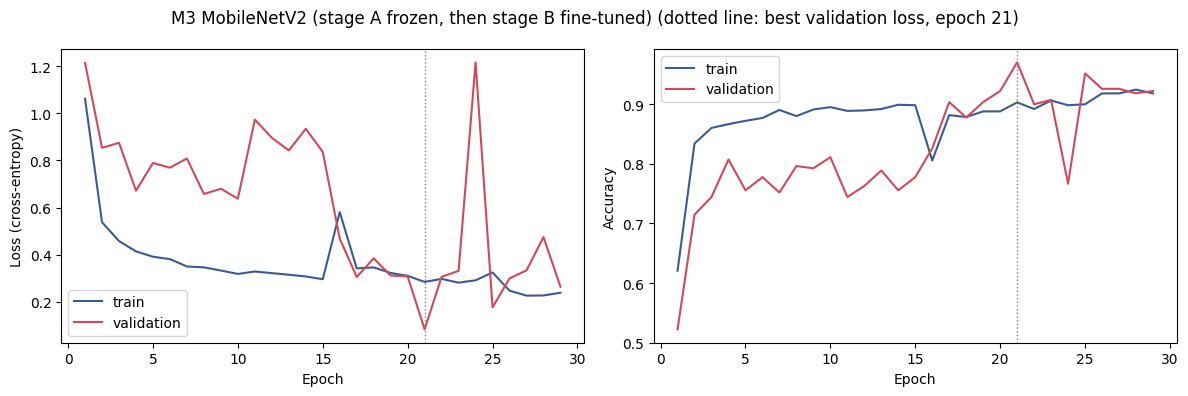

In [5]:
FINE_TUNE_FROM = 100
weights_a, best_loss_a = m3.get_weights(), float(hist_a["val_loss"].min())

base.trainable = True
for i, layer in enumerate(base.layers):
    # Batch norm stays frozen, so it keeps using the ImageNet statistics.
    layer.trainable = i >= FINE_TUNE_FROM and not isinstance(layer, keras.layers.BatchNormalization)
print("base layers:", len(base.layers), "| unfrozen from layer", FINE_TUNE_FROM,
      "| trainable layers:", sum(layer.trainable for layer in base.layers))
print("trainable weights in the base:", sum(int(np.prod(w.shape)) for w in base.trainable_weights))

hist_b, sec_b = train(m3, "m3_mobilenetv2", train_224, val_224, lr=1e-4, epochs=40, patience=8)
hist_m3 = pd.concat([hist_a, hist_b], ignore_index=True)
hist_m3.index.name = "epoch"
hist_m3["stage"] = ["A"] * len(hist_a) + ["B"] * len(hist_b)

# Keep whichever stage ended with the lower validation loss, and report the epoch those weights come from.
if float(hist_b["val_loss"].min()) <= best_loss_a:
    best = len(hist_a) + int(hist_b["val_loss"].idxmin())
    note = f"stage A {len(hist_a)} epochs + stage B {len(hist_b)} epochs, weights from stage B"
else:
    m3.set_weights(weights_a)
    best = int(hist_a["val_loss"].idxmin())
    note = f"stage A {len(hist_a)} epochs + stage B {len(hist_b)} epochs, stage B did not help: weights from stage A"
print(note)
record(m3, "m3_mobilenetv2", hist_m3, sec_a + sec_b, note, best=best)
plot_curves(hist_m3, "M3 MobileNetV2 (stage A frozen, then stage B fine-tuned)", "model_03_m3_curves.png")

## All three models on the validation set

M1 and M2 come from notebook 04. Validation accuracy and loss are taken at each model's best epoch; model size is the saved `.keras` file.

In [6]:
val_results = pd.concat([pd.read_csv(SCRATCH_RESULTS), pd.DataFrame(results)], ignore_index=True)
val_results.to_csv(RES_DIR / "val_results.csv", index=False)
val_results

,model,params,epochs_trained,best_epoch,val_accuracy,val_loss,train_accuracy_at_best,train_time_s,model_size_mb,note
0,m1_baseline,109958,100,100,0.9704,0.1056,0.9413,182.1,1.38,"3 conv blocks, no augmentation"
1,m2_improved,110630,41,29,0.9593,0.1310,0.9563,158.6,1.41,M1 + batch norm + augmentation
2,m3_mobilenetv2,2265670,29,21,0.9704,0.0832,0.9032,121.2,24.46,"stage A 15 epochs + stage B 14 epochs, weights..."


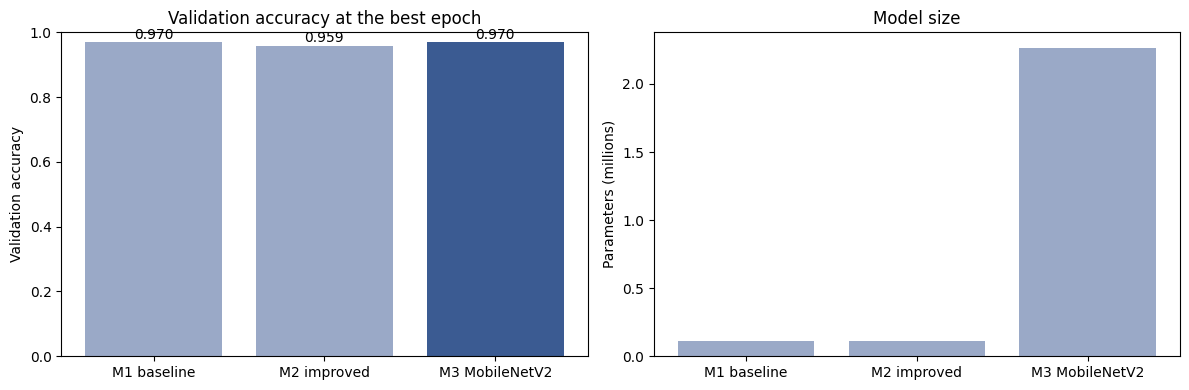

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
names = ["M1 baseline", "M2 improved", "M3 MobileNetV2"]
axes[0].bar(names, val_results["val_accuracy"], color=["#9aa9c7", "#9aa9c7", "#3b5b92"])
axes[0].set_ylabel("Validation accuracy")
axes[0].set_ylim(0, 1)
axes[0].set_title("Validation accuracy at the best epoch")
for i, v in enumerate(val_results["val_accuracy"]):
    axes[0].text(i, v + 0.01, f"{v:.3f}", ha="center")
axes[1].bar(names, val_results["params"] / 1e6, color="#9aa9c7")
axes[1].set_ylabel("Parameters (millions)")
axes[1].set_title("Model size")
fig.tight_layout()
fig.savefig(FIG_DIR / "model_04_validation_comparison.png", dpi=150)
plt.show()

## What we found

- **Frozen ImageNet features are not enough:** with only the new head trained (stage A), MobileNetV2 peaked at 81.11 % validation accuracy. Steel surface textures look nothing like the photos ImageNet was built from.
- **Fine-tuning from layer 100, with batch normalisation frozen, lifted it to 97.04 %**, the same validation accuracy as our M1 but with the lowest validation loss of the three models (0.083, against 0.106 for M1 and 0.131 for M2). A lower loss means the model is more confident when it is right.
- **It is much bigger:** 2,265,670 parameters and a 24.46 MB file, against 109,958 parameters and 1.38 MB for M1.
- **Finalists, chosen here on the validation set only:** M3 (lowest validation loss) and M1 (the best of our own CNNs, about 18 times smaller). The test set is opened once, in notebook 06.